# Analyse des valeurs marchandes

**Sommaire**

0. [Préparation des données](#Étape-0-:-préparation-des-données)
1. [Distribution des valeurs marchandes](#Étape-1-:-distribution-des-valeurs-marchandes)
2. [Valeur et âge](#Étape-2-:-valeur-et-âge)
3. [Valeur, poste et championnat](#Étape-3-:-valeur,-poste-et-championnat)
4. [Valeur et performances](#Étape-4-:-valeur-et-performances)
5. [Évolution de la valeur sur une saison](#Étape-5-:-évolution-de-la-valeur-sur-une-saison)
6. [Régressions linéaires](#Étape-6-:-régressions-linéaires)

## Étape 0 : préparation des données

On part du snapshot Transfermarkt : une ligne par joueur, avec sa valeur marchande au 30 juin 2026
et ses statistiques saison par saison.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

from valeur_marchande.transfermarkt import load_snapshot, load_panel

In [2]:
joueurs = load_snapshot()
joueurs.shape

(4796, 44)

On garde les joueurs qui ont joué au moins 900 minutes (l'équivalent de 10 matchs complets)
en 2025-26 : en dessous, leurs statistiques de la saison sont trop peu fiables.
On retire aussi le joueur dont le poste est inconnu.

In [3]:
MINUTES_MIN = 900
joueurs = joueurs.loc[(joueurs["minutes_2025_26"] >= MINUTES_MIN)
                      & (joueurs["position"] != "Missing")]
joueurs.shape

(2942, 44)

On traduit les codes des championnats et les postes, pour avoir des graphiques lisibles.

In [4]:
CHAMPIONNATS = {
    "GB1": "Premier League", "ES1": "Liga", "IT1": "Serie A", "L1": "Bundesliga",
    "FR1": "Ligue 1", "NL1": "Eredivisie", "PO1": "Liga Portugal", "BE1": "Pro League",
    "TR1": "Süper Lig",
}
POSTES = {"Goalkeeper": "Gardien", "Defender": "Défenseur", "Midfield": "Milieu",
          "Attack": "Attaquant"}

joueurs["championnat"] = joueurs["domestic_competition_id"].map(CHAMPIONNATS)
joueurs["poste"] = joueurs["position"].map(POSTES)
joueurs["valeur_millions"] = joueurs["market_value_in_eur"] / 1_000_000

joueurs[["name", "club_name", "championnat", "poste", "age", "valeur_millions"]].head()

,name,club_name,championnat,poste,age,valeur_millions
0,Erling Haaland,Manchester City,Premier League,Attaquant,25.0,200.0
1,Lamine Yamal,FC Barcelona,Liga,Attaquant,18.0,200.0
2,Kylian Mbappé,Real Madrid,Liga,Attaquant,27.0,180.0
3,Michael Olise,Bayern Munich,Bundesliga,Attaquant,24.0,150.0
4,Pedri,FC Barcelona,Liga,Milieu,23.0,150.0


## Étape 1 : distribution des valeurs marchandes

In [5]:
joueurs["valeur_millions"].describe().round(1)

count    2942.0
mean       12.0
std        18.0
min         0.0
25%         1.8
50%         5.0
75%        15.0
max       200.0
Name: valeur_millions, dtype: float64

> **Commentaires :** médiane de 5 M€ mais moyenne de 12 M€,
> la distribution est très asymétrique, tirée par quelques stars à 150-200 M€.

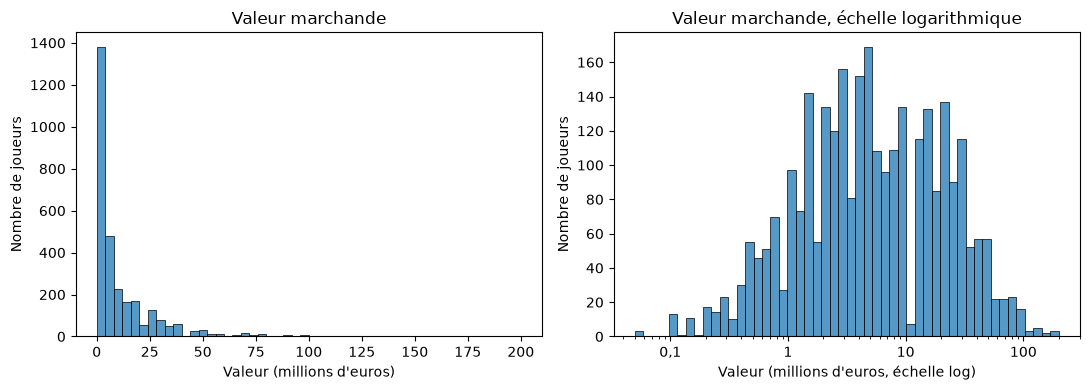

In [6]:
# Graduations de l'axe en échelle logarithmique, écrites en clair
GRADUATIONS = [0.1, 1, 10, 100]
ETIQUETTES = ["0,1", "1", "10", "100"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(data=joueurs, x="valeur_millions", bins=50, ax=axes[0])
axes[0].set(title="Valeur marchande", xlabel="Valeur (millions d'euros)",
            ylabel="Nombre de joueurs")

sns.histplot(data=joueurs, x="valeur_millions", bins=50, log_scale=True, ax=axes[1])
axes[1].set_xticks(GRADUATIONS, labels=ETIQUETTES)
axes[1].set(title="Valeur marchande, échelle logarithmique",
            xlabel="Valeur (millions d'euros, échelle log)", ylabel="Nombre de joueurs")

plt.tight_layout()
plt.show()

> **Commentaires :** En échelle normale on ne voit rien à cause des stars ; en échelle log
> (chaque graduation multiplie la valeur par 10) la distribution devient lisible, d'où l'intérêt
> de raisonner en log et en médianes. Les « pics » viennent des valeurs arrondies de
> Transfermarkt (1,5 M, 2 M, 5 M…).

## Étape 2 : valeur et âge

À quel âge un joueur vaut-il le plus cher ? On trace la valeur médiane à chaque âge
(on garde les âges représentés par au moins 20 joueurs).

In [7]:
effectifs_age = joueurs["age"].value_counts()
ages_retenus = effectifs_age[effectifs_age >= 20].index
joueurs_age = joueurs.loc[joueurs["age"].isin(ages_retenus)]

print(f"Âges retenus : de {ages_retenus.min():.0f} à {ages_retenus.max():.0f} ans")

Âges retenus : de 19 à 36 ans


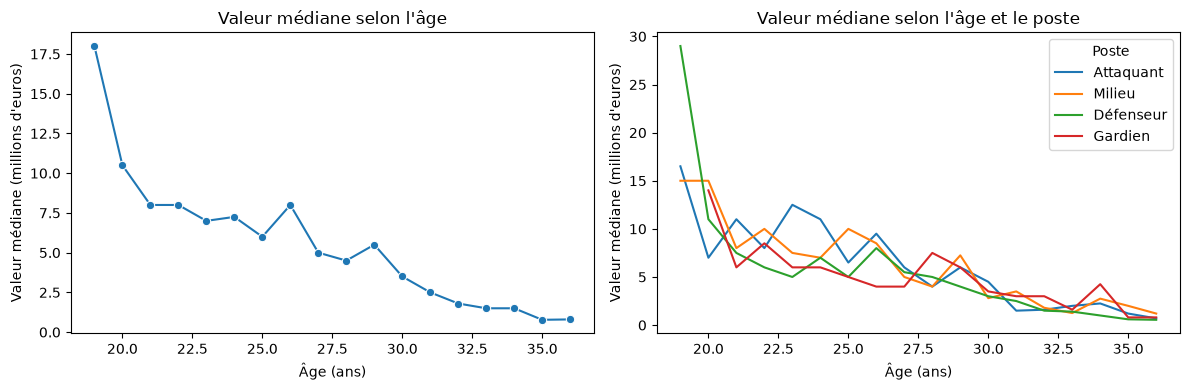

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.lineplot(data=joueurs_age, x="age", y="valeur_millions", estimator="median",
             errorbar=None, marker="o", ax=axes[0])
axes[0].set(title="Valeur médiane selon l'âge", xlabel="Âge (ans)",
            ylabel="Valeur médiane (millions d'euros)")

sns.lineplot(data=joueurs_age, x="age", y="valeur_millions", hue="poste", estimator="median",
             errorbar=None, ax=axes[1])
axes[1].set(title="Valeur médiane selon l'âge et le poste", xlabel="Âge (ans)",
            ylabel="Valeur médiane (millions d'euros)")
axes[1].legend(title="Poste")

plt.tight_layout()
plt.show()

In [9]:
# Âge où la valeur médiane est la plus haute
mediane_par_age = joueurs_age.groupby("age")["valeur_millions"].median()
print(f"Pic de valeur médiane : {mediane_par_age.idxmax():.0f} ans "
      f"({mediane_par_age.max():.1f} M€)")

Pic de valeur médiane : 19 ans (18.0 M€)


> **Commentaires :** la valeur médiane est la plus haute chez les plus jeunes et baisse
> presque continûment avec l'âge, surtout après 30 ans, alors qu'un joueur de 30 ans peut être
> aussi performant : le marché paie le potentiel et la durée de carrière restante.
> Attention à un effet de sélection : un joueur de 19 ans qui joue 900 minutes dans ces
> championnats est déjà exceptionnel. Les postes suivent à peu près la même courbe.
> La baisse n'est pas une droite (elle s'accélère) : on en tiendra compte dans la
> régression (étape 6) avec un terme âge².

## Étape 3 : valeur, poste et championnat

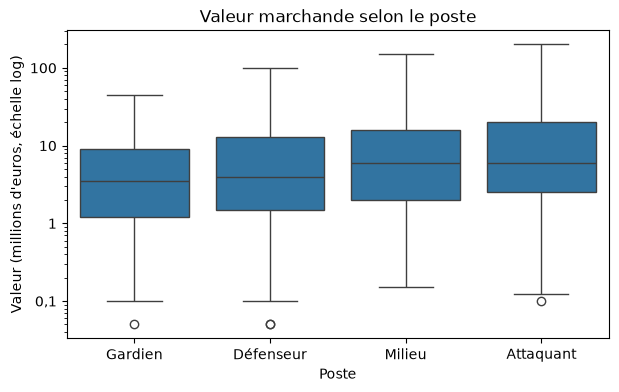

In [10]:
ORDRE_POSTES = ["Gardien", "Défenseur", "Milieu", "Attaquant"]

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=joueurs, x="poste", y="valeur_millions", order=ORDRE_POSTES,
            log_scale=True, ax=ax)
ax.set_yticks(GRADUATIONS, labels=ETIQUETTES)
ax.set(title="Valeur marchande selon le poste", xlabel="Poste",
       ylabel="Valeur (millions d'euros, échelle log)")
plt.show()

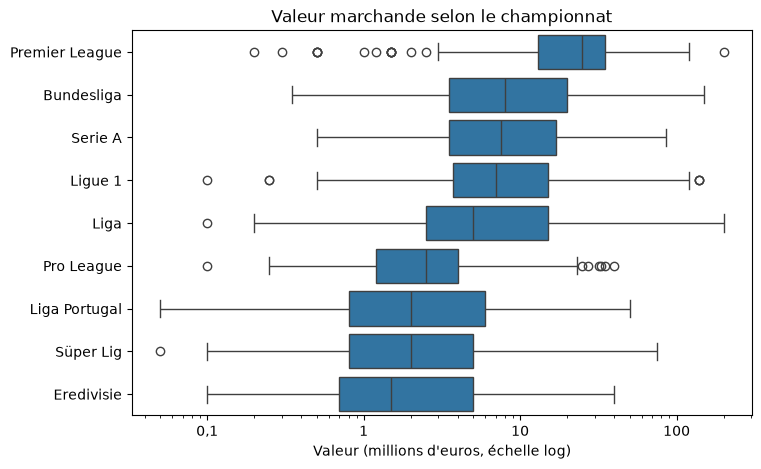

In [11]:
ordre_championnats = (
    joueurs
    .groupby("championnat")["valeur_millions"]
    .median()
    .sort_values(ascending=False)
    .index
)

# Boîtes horizontales : les noms des championnats restent lisibles
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=joueurs, x="valeur_millions", y="championnat", order=ordre_championnats,
            log_scale=True, ax=ax)
ax.set_xticks(GRADUATIONS, labels=ETIQUETTES)
ax.set(title="Valeur marchande selon le championnat",
       xlabel="Valeur (millions d'euros, échelle log)", ylabel="")
plt.show()

Pour comparer les postes **à championnat égal**, on croise les deux : valeur médiane
(en millions d'euros) pour chaque championnat et chaque poste.

In [12]:
pd.pivot_table(joueurs, values="valeur_millions", index="championnat", columns="poste",
               aggfunc="median").loc[ordre_championnats, ORDRE_POSTES].round(1)

poste,Gardien,Défenseur,Milieu,Attaquant
championnat,,,,
Premier League,13.0,22.0,25.0,28.0
Bundesliga,6.0,6.0,10.0,10.0
Serie A,3.8,7.0,8.0,10.0
Ligue 1,5.5,8.0,8.0,8.0
Liga,4.0,4.0,5.0,6.5
Pro League,2.0,2.0,2.1,3.0
Liga Portugal,2.0,1.5,3.0,1.9
Süper Lig,1.5,1.8,2.0,2.0
Eredivisie,2.0,1.5,1.6,1.9


> **Commentaires :** l'écart entre championnats (Premier League très au-dessus) est
> bien plus grand que l'écart entre postes ; dans chaque championnat, les gardiens valent moins
> que les joueurs de champ. Le championnat est donc une variable à contrôler absolument.

## Étape 4 : valeur et performances

Les joueurs n'ont pas tous joué le même temps : on ramène les buts et les passes décisives
de la saison 2025-26 à **90 minutes de jeu** (un match complet).

In [13]:
def ajouter_stats_par_90(df, saison):
    """Ajoute les buts, passes décisives et contributions (buts + passes) par 90 minutes
    pour une saison donnée (ex. "2025_26")."""
    minutes = df[f"minutes_{saison}"]
    df["buts_90"] = df[f"goals_{saison}"] / minutes * 90
    df["passes_90"] = df[f"assists_{saison}"] / minutes * 90
    df["contributions_90"] = df["buts_90"] + df["passes_90"]
    return df


joueurs = ajouter_stats_par_90(joueurs, "2025_26")
joueurs[["name", "poste", "minutes_2025_26", "buts_90", "passes_90"]].head()

,name,poste,minutes_2025_26,buts_90,passes_90
0,Erling Haaland,Attaquant,4325,0.894798,0.187283
1,Lamine Yamal,Attaquant,3842,0.585632,0.421655
2,Kylian Mbappé,Attaquant,4023,1.051454,0.201342
3,Michael Olise,Attaquant,4238,0.467202,0.722039
4,Pedri,Milieu,3314,0.054315,0.325890


In [14]:
# Meilleurs buteurs par 90 minutes
(
    joueurs
    .sort_values("buts_90", ascending=False)
    .loc[:, ["name", "club_name", "minutes_2025_26", "goals_2025_26", "buts_90",
             "valeur_millions"]]
    .head(10)
    .round(2)
)

,name,club_name,minutes_2025_26,goals_2025_26,buts_90,valeur_millions
78,Harry Kane,Bayern Munich,4314,61,1.27,60.0
2,Kylian Mbappé,Real Madrid,4023,47,1.05,180.0
621,Orri Óskarsson,Real Sociedad,912,10,0.99,20.0
13,Ousmane Dembélé,Paris Saint-Germain,2363,24,0.91,100.0
2190,Raúl García,CA Osasuna,1384,14,0.91,3.0
2386,Victor Jensen,FC Utrecht,1088,11,0.91,2.5
339,Ricardo Pepi,PSV Eindhoven,1888,19,0.91,30.0
0,Erling Haaland,Manchester City,4325,43,0.89,200.0
405,Troy Parrott,AZ Alkmaar,2995,28,0.84,25.0
1338,Talisca,Fenerbahce,2576,24,0.84,7.0


On regarde le lien entre contributions par 90 minutes et valeur, poste par poste
(sans les gardiens, qui ne marquent presque jamais).

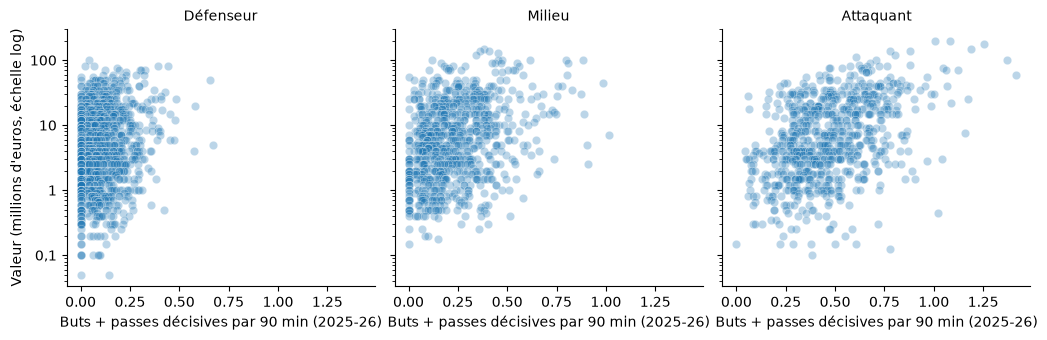

In [15]:
joueurs_champ = joueurs.loc[joueurs["poste"] != "Gardien"]

grille = sns.relplot(data=joueurs_champ, x="contributions_90", y="valeur_millions",
                     col="poste", col_order=["Défenseur", "Milieu", "Attaquant"],
                     alpha=0.3, height=3.5)
grille.set(yscale="log")
grille.set_axis_labels("Buts + passes décisives par 90 min (2025-26)",
                       "Valeur (millions d'euros, échelle log)")
grille.set_titles("{col_name}")
for ax in grille.axes.flat:
    ax.set_yticks(GRADUATIONS, labels=ETIQUETTES)
plt.show()

Comme la valeur est très asymétrique, on utilise la **corrélation de Spearman**, qui compare
les rangs des joueurs et n'est pas écrasée par quelques valeurs extrêmes.

In [16]:
VARIABLES = ["age", "minutes_2025_26", "buts_90", "passes_90", "contributions_90"]

correlations = {}
for poste in ORDRE_POSTES:
    joueurs_poste = joueurs.loc[joueurs["poste"] == poste]
    correlations[poste] = (
        joueurs_poste[VARIABLES]
        .corrwith(joueurs_poste["valeur_millions"], method="spearman")
    )

pd.DataFrame(correlations).round(2)

,Gardien,Défenseur,Milieu,Attaquant
age,-0.44,-0.37,-0.36,-0.31
minutes_2025_26,0.50,0.40,0.43,0.43
buts_90,-0.05,0.16,0.28,0.32
passes_90,0.09,0.13,0.27,0.27
contributions_90,0.07,0.17,0.32,0.42


> **Commentaires :** les contributions offensives sont liées à la valeur surtout pour
> les attaquants et les milieux, beaucoup moins pour les défenseurs (leur travail n'apparaît pas
> dans les buts et passes). Le temps de jeu est fortement lié à la valeur à tous les postes :
> mais il peut être une conséquence (un joueur cher joue plus) autant qu'une cause.
> Corrélation n'est pas causalité.

## Étape 5 : évolution de la valeur sur une saison

On utilise le panel : une ligne par joueur et par saison, avec sa valeur au début et à la fin
de la saison. On mesure la variation en log, qu'on convertit en pourcentage
(une variation de log de 0,1 correspond à environ +10,5 %).

In [17]:
panel = load_panel()
panel = panel.loc[(panel["minutes"] >= MINUTES_MIN)
                  & panel["log_value_change"].notna()
                  & (panel["position"] != "Missing")]
panel["poste"] = panel["position"].map(POSTES)
panel["variation_pct"] = (np.exp(panel["log_value_change"]) - 1) * 100
panel["contributions_90"] = (panel["goals"] + panel["assists"]) / panel["minutes"] * 90

print(panel.shape)
panel["season"].value_counts().sort_index()

(11406, 28)


season
2022_23    2886
2023_24    2873
2024_25    2737
2025_26    2910
Name: count, dtype: int64

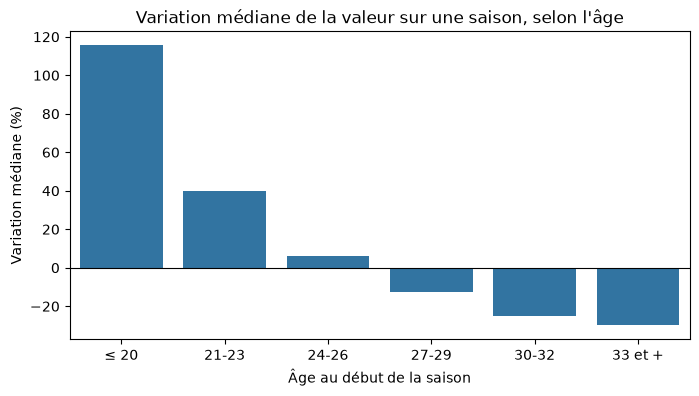

In [18]:
panel["tranche_age"] = pd.cut(panel["age"], bins=[0, 20, 23, 26, 29, 32, 45],
                              labels=["≤ 20", "21-23", "24-26", "27-29", "30-32", "33 et +"])

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=panel, x="tranche_age", y="variation_pct", estimator="median",
            errorbar=None, ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Variation médiane de la valeur sur une saison, selon l'âge",
       xlabel="Âge au début de la saison", ylabel="Variation médiane (%)")
plt.show()

Pour les attaquants, on compare la variation de valeur selon leurs contributions de la
saison, en 4 groupes de même taille (quartiles).

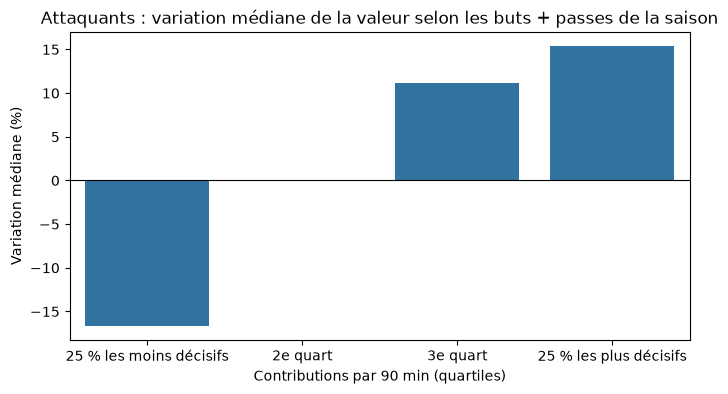

In [19]:
attaquants = panel.loc[panel["poste"] == "Attaquant"].copy()
attaquants["quartile_contributions"] = pd.qcut(
    attaquants["contributions_90"], q=4,
    labels=["25 % les moins décisifs", "2e quart", "3e quart", "25 % les plus décisifs"])

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=attaquants, x="quartile_contributions", y="variation_pct",
            estimator="median", errorbar=None, ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Attaquants : variation médiane de la valeur selon les buts + passes de la saison",
       xlabel="Contributions par 90 min (quartiles)", ylabel="Variation médiane (%)")
plt.show()

> **Commentaires :** les jeunes prennent de la valeur presque mécaniquement (plus de
> +100 % en médiane avant 21 ans), les plus de 27 ans en perdent même quand ils jouent.
> Chez les attaquants, les 25 % les moins décisifs perdent environ 17 % de valeur et les 25 %
> les plus décisifs en gagnent environ 15 % : les performances *récentes* comptent.
> La médiane à 0 du 2e quart signifie qu'au moins la moitié de ces joueurs ont gardé exactement
> la même valeur (Transfermarkt ne revoit pas toutes les valeurs chaque saison).